# PROJECT CAPSTONE DBS

**Judul Proyek:** BilahBeu AI: Platform AI Terintegrasi untuk Klasifikasi Sampah Rumah Tangga dan Edukasi Lingkungan Berbasis Web

**Deskripsi Proyek:** BilahBeu AI, yaitu platform web berbasis AI (Computer Vision) yang memungkinkan pengguna mengunggah foto sampah untuk menerima hasil klasifikasi secara instan beserta panduan pengelolaan yang sesuai.


# Required Dependencies


In [1]:
!pip install tensorflowjs
!pip install split-folders

INFO: pip is looking at multiple versions of tf-keras to determine which version is compatible with other requirements. This could take a while.
INFO: pip is looking at multiple versions of wheel to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.1/89.1 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.0/53.0 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.1/16.1 MB 57.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 645.0/645.0 MB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 69.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 94.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.5/72.5 kB 7.5 MB/s eta 0:00:00
  Attempting uninstall: wheel
    Found existing installation: wheel 0.47.0
    Uninstalling wheel-0.47.0:
      Successfully uninstalled wheel-0.47.0
  Attempting un

In [1]:
#--------1.Instal liblary-------#

# TensorFlow and Keras imports
import warnings
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.preprocessing import image
from tensorflow.keras.models import load_model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout, BatchNormalization
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

# Scikit-learn imports
from sklearn.metrics import classification_report, confusion_matrix

# Other imports
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image
import glob

In [2]:
#--------2.hubungkan drive-------#

from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


# Data Visualization

In [3]:
#--------3.cek isi folder-------#

import os

# Path di Google Drive
source_folder = '/content/drive/Shareddrives/projectDBS/Dataset/Dataset_Siap_Pakai'

# Cek apakah folder ada dan tampilkan isinya
if os.path.exists(source_folder):
    print(f"Folder ditemukan di: {source_folder}")
    content = os.listdir(source_folder)
    print(f"Jumlah item: {len(content)}")
    print("Isi folder:", content[:10])
else:
    print(f"Gagal: Folder tidak ditemukan di {source_folder}.")
    print("Tips: Pastikan drive sudah ter-mount dan path sudah benar.")

Folder ditemukan di: /content/drive/Shareddrives/projectDBS/Dataset/Dataset_Siap_Pakai
Jumlah item: 3
Isi folder: ['B3', 'Organik', 'Anorganik']


Number of training samples in class 'B3': 1040


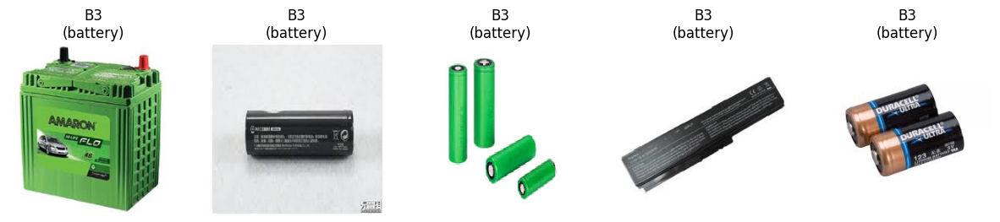

Number of training samples in class 'Organik': 2613


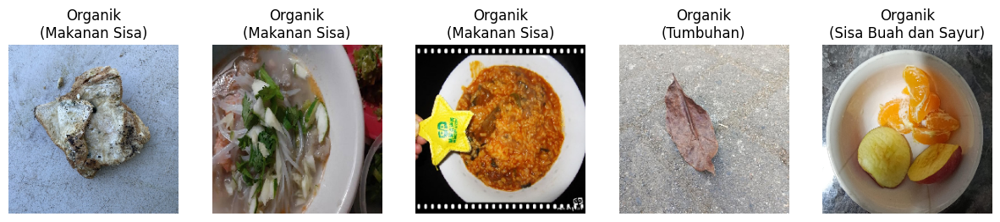

Number of training samples in class 'Anorganik': 5686


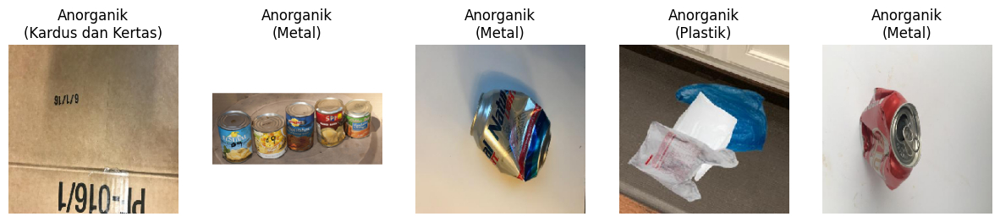

In [4]:
#--------4.ambil sempel dari tiap kategori-------#

import glob
import os
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import load_img, img_to_array

# Define the training directory directly from Google Drive
train_dir = '/content/drive/Shareddrives/projectDBS/Dataset/Dataset_Siap_Pakai'

# Visualize and count the number of images in each class (searching recursively)
class_names = [d for d in os.listdir(train_dir) if os.path.isdir(os.path.join(train_dir, d))]

for class_name in class_names:
    class_dir = os.path.join(train_dir, class_name)
    # Search recursively (**/) for all common image extensions
    class_images = []
    for ext in ('**/*.jpg', '**/*.jpeg', '**/*.png', '**/*.JPG', '**/*.JPEG', '**/*.PNG'):
        class_images.extend(glob.glob(os.path.join(class_dir, ext), recursive=True))

    print(f"Number of training samples in class '{class_name}': {len(class_images)}")

    if len(class_images) > 0:
        plt.figure(figsize=(15, 5))
        num_show = min(5, len(class_images))
        for i in range(num_show):
            plt.subplot(1, 5, i+1)
            img_path = np.random.choice(class_images)
            try:
                img = load_img(img_path, target_size=(224, 224))
                img_array = img_to_array(img) / 255.0
                plt.imshow(img_array)
                plt.axis('off')
                # Show the immediate parent folder name for better context
                sub_class = os.path.basename(os.path.dirname(img_path))
                plt.title(f"{class_name}\n({sub_class})")
            except Exception as e:
                print(f"Could not load image {img_path}: {e}")
        plt.show()
    else:
        print(f"No images found in {class_name} or its subfolders.")

# DATA SPLITING

In [18]:
#--------5 clean folder-------#

import shutil
import os

# Daftar folder yang ingin dihapus
folders_to_remove = ['/content/dataset_model']

for folder in folders_to_remove:
    if os.path.exists(folder):
        try:
            shutil.rmtree(folder)
            print(f"Berhasil menghapus folder: {folder}")
        except Exception as e:
            print(f"Gagal menghapus {folder}: {e}")
    else:
        print(f"Folder tidak ditemukan (sudah terhapus): {folder}")

Berhasil menghapus folder: /content/dataset_model


In [5]:
#--------6.mengambil semua class di drive-------#



import os
import shutil
import splitfolders

# 1. Path Sumber (Drive)
source_root = '/content/drive/Shareddrives/projectDBS/Dataset/Dataset_Siap_Pakai'
# 2. Folder sementara (Datar/Flat)
flat_dir = '/content/flat_dataset'
# 3. Folder akhir (Hasil Split)
output_dir = '/content/dataset_model'

if os.path.exists(flat_dir):
    shutil.rmtree(flat_dir)
os.makedirs(flat_dir)

# Daftar folder induk yang ada di Drive
parent_folders = ['Anorganik', 'Organik', 'B3']

print("Sedang memproses pemindahan folder...")

for parent in parent_folders:
    parent_path = os.path.join(source_root, parent)

    if os.path.exists(parent_path):
        # Ambil semua subfolder di dalamnya (botol, kaca, metal, dll)
        subfolders = [f for f in os.listdir(parent_path) if os.path.isdir(os.path.join(parent_path, f))]

        for sub in subfolders:
            src_sub_path = os.path.join(parent_path, sub)
            dst_sub_path = os.path.join(flat_dir, sub)

            # Salin foldernya ke flat_dir
            if not os.path.exists(dst_sub_path):
                shutil.copytree(src_sub_path, dst_sub_path)
                print(f"Berhasil menarik folder: {sub}")


Sedang memproses pemindahan folder...
Berhasil menarik folder: Botol Plastik
Berhasil menarik folder: Plastik
Berhasil menarik folder: Metal
Berhasil menarik folder: Kaca
Berhasil menarik folder: Pakaian
Berhasil menarik folder: Kardus dan Kertas
Berhasil menarik folder: Tumbuhan
Berhasil menarik folder: Makanan Sisa
Berhasil menarik folder: Sisa Buah dan Sayur
Berhasil menarik folder: battery


In [7]:
#---- menyimpan flat_dataset ke grive---#

import shutil
import os

# 1. Tentukan path asal dan tujuan
source_dir = '/content/flat_dataset'
destination_drive_path = '/content/drive/MyDrive/dataset/flat_dataset_backup'

# 2. Pastikan folder tujuan di Drive sudah ada
os.makedirs('/content/drive/MyDrive/dataset', exist_ok=True)

# 3. Lakukan kompresi ke format ZIP
if os.path.exists(source_dir):
    print(f"Sedang mengompres {source_dir}...")
    shutil.make_archive(destination_drive_path, 'zip', source_dir)
    print(f"Berhasil! File ZIP disimpan di: {destination_drive_path}.zip")
else:
    print(f"Gagal: Folder {source_dir} tidak ditemukan.")

Sedang mengompres /content/flat_dataset...
Berhasil! File ZIP disimpan di: /content/drive/MyDrive/dataset/flat_dataset_backup.zip


In [ ]:
#----Import dataset dari gdrive-----#
import zipfile
import os

# Tentukan path file zip di Drive dan folder tujuan ekstraksi
zip_path = '/content/drive/MyDrive/dataset/flat_dataset_backup.zip'
extract_path = '/content/flat_dataset'

# Lakukan ekstraksi jika file ada
if os.path.exists(zip_path):
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)
    print(f"Berhasil mengekstrak ke: {extract_path}")
else:
    print(f"Error: File {zip_path} tidak ditemukan.")

Berhasil mengekstrak ke: /content/flat_dataset


In [19]:
#----cek dataset---#
import os
from PIL import Image

data_dir = '/content/flat_dataset'
count_corrupt = 0

print(f"--- Memeriksa gambar di: {data_dir} ---")

# Loop melalui semua subfolder dan file
for root, dirs, files in os.walk(data_dir):
    for filename in files:
        if filename.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.gif')):
            filepath = os.path.join(root, filename)
            try:
                img = Image.open(filepath)
                img.verify() # Memverifikasi integritas file
            except (IOError, SyntaxError, Image.UnidentifiedImageError) as e:
                print(f"Menghapus file rusak: {filepath} | Alasan: {e}")
                os.remove(filepath)
                count_corrupt += 1

print(f"\nProses Selesai!")
print(f"Total file rusak yang dihapus: {count_corrupt}")

--- Memeriksa gambar di: /content/flat_dataset ---

Proses Selesai!
Total file rusak yang dihapus: 0


In [20]:
# !pip install split-folders
import splitfolders

# Define paths for splitting
flat_dir = '/content/flat_dataset'
output_dir = '/content/dataset_model'

# Bagi menjadi Train (70%), Val (20%), Test (10%)
splitfolders.ratio(flat_dir, output=output_dir, seed=1337, ratio=(.7, .2, .1))

print("--- PROSES SELESAI ---")
print(f"Cek folder: {output_dir}/train")

Copying files: 9241 files [00:02, 3269.55 files/s]

--- PROSES SELESAI ---
Cek folder: /content/dataset_model/train


# Data Augmentasi

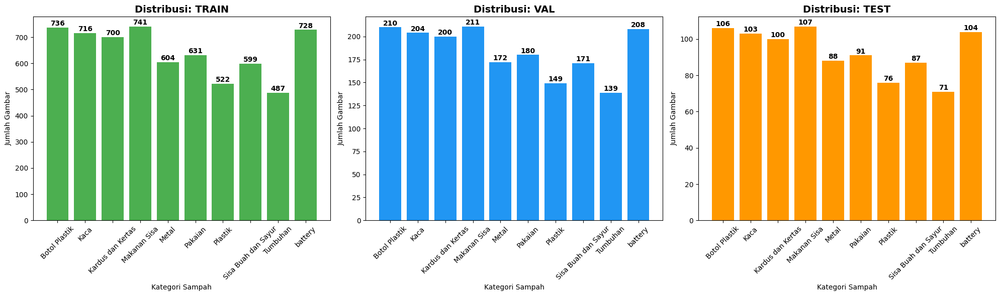

In [21]:
#--------8.cek data sebelum augmentasi-------#

import os
import matplotlib.pyplot as plt

def plot_dataset_distribution(root_path):
    # Nama folder split
    splits = ['train', 'val', 'test']

    # Menyiapkan area plot (1 baris, 3 kolom)
    fig, axes = plt.subplots(1, 3, figsize=(20, 6))
    colors = ['#4CAF50', '#2196F3', '#FF9800'] # Hijau, Biru, Oranye

    for i, split in enumerate(splits):
        split_path = os.path.join(root_path, split)
        if not os.path.exists(split_path):
            print(f"Folder {split} tidak ditemukan!")
            continue

        # Ambil nama kelas dan jumlah gambarnya
        classes = sorted(os.listdir(split_path))
        counts = [len(os.listdir(os.path.join(split_path, c))) for c in classes]

        # Membuat bar chart
        axes[i].bar(classes, counts, color=colors[i])
        axes[i].set_title(f'Distribusi: {split.upper()}', fontsize=14, fontweight='bold')
        axes[i].set_xlabel('Kategori Sampah')
        axes[i].set_ylabel('Jumlah Gambar')
        axes[i].tick_params(axis='x', rotation=45)

        # Menambahkan angka di atas batang
        for j, v in enumerate(counts):
            axes[i].text(j, v + (max(counts)*0.01), str(v), ha='center', fontweight='bold')

    plt.tight_layout()
    plt.show()

# Jalankan fungsi untuk folder dataset kamu
plot_dataset_distribution('/content/dataset_model')

In [22]:
#--proses agumentasi---#

import os
from tensorflow.keras.preprocessing.image import ImageDataGenerator, img_to_array, load_img
from PIL import UnidentifiedImageError

# Tentukan target minimal tiap kelas
TARGET_MINIMAL = 1000
train_dir = '/content/dataset_model/train'

# Setup alat untuk membuat gambar baru
datagen_oversample = ImageDataGenerator(
    rotation_range=40,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    brightness_range=[0.5, 1.5],
    horizontal_flip=True,
    fill_mode='nearest'
)

print("--- Memulai Proses Penambahan File Fisik ---")

for category in os.listdir(train_dir):
    category_path = os.path.join(train_dir, category)
    if not os.path.isdir(category_path): continue

    # Filter hanya file gambar
    valid_extensions = ('.png', '.jpg', '.jpeg', '.gif', '.bmp')
    images = [img_name for img_name in os.listdir(category_path) if img_name.lower().endswith(valid_extensions)]

    current_count = len(images)

    if current_count < TARGET_MINIMAL:
        print(f"Menambah data untuk kelas: {category} ({current_count} -> {TARGET_MINIMAL})")
        diff = TARGET_MINIMAL - current_count

        i = 0
        while i < diff:
            for img_name in images:
                if i >= diff: break

                img_path = os.path.join(category_path, img_name)
                try:
                    img = load_img(img_path)
                    x = img_to_array(img)
                    x = x.reshape((1,) + x.shape)

                    # Generate dan SIMPAN ke folder secara fisik
                    for batch in datagen_oversample.flow(x, batch_size=1,
                                              save_to_dir=category_path,
                                              save_prefix='AUG_NEW',
                                              save_format='jpeg'):
                        i += 1
                        break
                except (UnidentifiedImageError, OSError):
                    print(f"Melewati file rusak: {img_name}")
                    continue

print("\nSelesai! Sekarang silakan jalankan ulang kode diagram batangmu.")

--- Memulai Proses Penambahan File Fisik ---
Menambah data untuk kelas: Tumbuhan (487 -> 1000)
Menambah data untuk kelas: battery (728 -> 1000)
Menambah data untuk kelas: Pakaian (631 -> 1000)
Menambah data untuk kelas: Sisa Buah dan Sayur (599 -> 1000)
Menambah data untuk kelas: Metal (604 -> 1000)
Menambah data untuk kelas: Plastik (522 -> 1000)
Menambah data untuk kelas: Botol Plastik (736 -> 1000)
Menambah data untuk kelas: Kaca (716 -> 1000)
Menambah data untuk kelas: Kardus dan Kertas (700 -> 1000)
Menambah data untuk kelas: Makanan Sisa (741 -> 1000)

Selesai! Sekarang silakan jalankan ulang kode diagram batangmu.


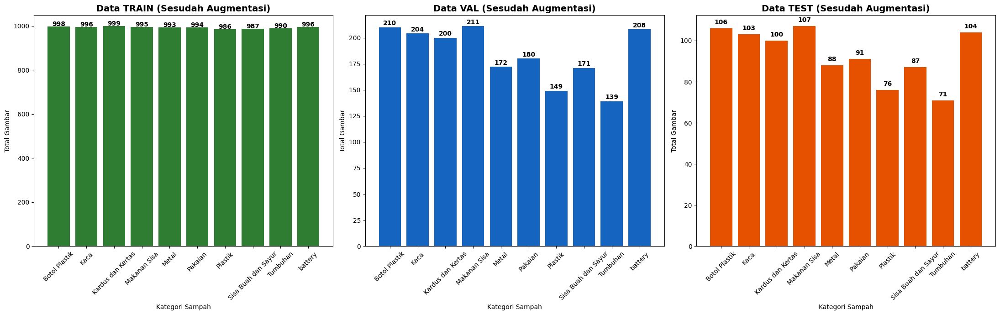

In [23]:
#--------10.cek data setelah augmentasi-------#

import os
import matplotlib.pyplot as plt

def plot_final_distribution(root_path):
    # Nama folder split
    splits = ['train', 'val', 'test']

    # Menyiapkan area plot (1 baris, 3 kolom)
    fig, axes = plt.subplots(1, 3, figsize=(22, 7))
    colors = ['#2E7D32', '#1565C0', '#E65100'] # Hijau Tua, Biru Tua, Oranye Tua

    for i, split in enumerate(splits):
        split_path = os.path.join(root_path, split)
        if not os.path.exists(split_path):
            continue

        # Ambil nama kelas dan jumlah gambarnya (disortir agar urutannya sama di 3 grafik)
        classes = sorted(os.listdir(split_path))
        counts = []
        for c in classes:
            class_path = os.path.join(split_path, c)
            if os.path.isdir(class_path):
                counts.append(len(os.listdir(class_path)))

        # Membuat bar chart
        axes[i].bar(classes, counts, color=colors[i])
        axes[i].set_title(f'Data {split.upper()} (Sesudah Augmentasi)', fontsize=14, fontweight='bold')
        axes[i].set_xlabel('Kategori Sampah')
        axes[i].set_ylabel('Total Gambar')
        axes[i].tick_params(axis='x', rotation=45)

        # Menambahkan angka di atas batang untuk kepastian jumlah
        for j, v in enumerate(counts):
            axes[i].text(j, v + 2, str(v), ha='center', fontweight='bold', fontsize=10)

    plt.tight_layout()
    plt.show()

# Jalankan fungsi cek
plot_final_distribution('/content/dataset_model')

In [24]:
#--------11.set config-------#

# Set parameters
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# 1. Generator untuk TRAIN (dengan Augmentasi)
train_datagen = ImageDataGenerator(
    rescale=1.0/255,
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    brightness_range=[0.5, 1.5],
    horizontal_flip=True,
    fill_mode='nearest'
)

# 2. Generator untuk VALIDATION & TEST (Tanpa Augmentasi, hanya Rescale)
# Kita pisahkan agar evaluasi tetap pada gambar asli
val_test_datagen = ImageDataGenerator(rescale=1.0/255)

# --- Aliran Data ---

train_generator = train_datagen.flow_from_directory(
    directory='/content/dataset_model/train',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical' # Pastikan categorical karena 11 kelas
)

validation_generator = val_test_datagen.flow_from_directory(
    directory='/content/dataset_model/val',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

test_generator = val_test_datagen.flow_from_directory(
    directory='/content/dataset_model/test',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False # Penting untuk evaluasi akhir (Confusion Matrix)
)

Found 9934 images belonging to 10 classes.
Found 1844 images belonging to 10 classes.
Found 933 images belonging to 10 classes.


In [25]:
# Get class labels from the training dataset
class_labels = train_generator.class_indices  # returns a dictionary of class names and their indices

# Print the class labels and their corresponding encoded values
print("Class Labels and Encoded Values:")
print(class_labels)

reversed_labels = {v: k for k, v in class_labels.items()}
print("\nReversed Encoded Labels:")
print(reversed_labels)


Class Labels and Encoded Values:
{'Botol Plastik': 0, 'Kaca': 1, 'Kardus dan Kertas': 2, 'Makanan Sisa': 3, 'Metal': 4, 'Pakaian': 5, 'Plastik': 6, 'Sisa Buah dan Sayur': 7, 'Tumbuhan': 8, 'battery': 9}

Reversed Encoded Labels:
{0: 'Botol Plastik', 1: 'Kaca', 2: 'Kardus dan Kertas', 3: 'Makanan Sisa', 4: 'Metal', 5: 'Pakaian', 6: 'Plastik', 7: 'Sisa Buah dan Sayur', 8: 'Tumbuhan', 9: 'battery'}


In [26]:
# Import necessary callbacks
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

# Define the path for saving model weights
filepath = './final_model_weights.keras'  # Change the extension to .keras

# Early stopping callback: monitors the validation accuracy
earlystopping = EarlyStopping(monitor='val_accuracy',  # Monitors validation accuracy
                              mode='max',         # Stops when the validation accuracy does not improve
                              patience=5,         # Patience is the number of epochs with no improvement before stopping
                              verbose=1)          # Prints messages when stopping

# Model checkpoint callback: saves the best model based on validation accuracy
checkpoint = ModelCheckpoint(filepath,            # Filepath to save the best model weights
                              monitor='val_accuracy',  # Monitors validation accuracy
                              mode='max',         # Save the model with the highest accuracy
                              save_best_only=True,  # Only save the best model
                              verbose=1)          # Prints messages when saving the model

# Reduce learning rate when a metric has stopped improving.
reduce_lr = ReduceLROnPlateau(monitor='val_accuracy', factor=0.2, patience=3, verbose=1, mode='max', min_lr=0.00001)

# List of callbacks to use during training
callback_list = [earlystopping, checkpoint, reduce_lr]

### Menambahkan TensorBoard untuk Monitoring

In [27]:
import datetime

# Setup direktori log untuk TensorBoard
log_dir = "logs/fit/" + datetime.datetime.now().strftime("%Y%m%d-%H%M%S")
tensorboard_callback = tf.keras.callbacks.TensorBoard(log_dir=log_dir, histogram_freq=1)

# Tambahkan ke callback_list yang sudah ada
callback_list.append(tensorboard_callback)

print(f"TensorBoard callback ditambahkan. Log akan disimpan di: {log_dir}")

TensorBoard callback ditambahkan. Log akan disimpan di: logs/fit/20260517-073705


# Model Development

In [28]:


# Base model: MobileNetV2 pre-trained on ImageNet
base_model = MobileNetV2(input_shape=(224, 224, 3),  # Adjust input size as per your requirements
                          include_top=False,          # Exclude the top classification layers
                          weights="imagenet")         # Load pre-trained weights from ImageNet


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [29]:
# Freezing all layers in the base model
for layer in base_model.layers:
    layer.trainable = False


In [30]:
#--------12.set config model-------#

# Import necessary modules
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Flatten, BatchNormalization
from tensorflow.keras.applications import MobileNetV2

# Load the pretrained MobileNetV2 model without the top (fully connected) layers
base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
base_model.trainable = False  # Freeze the base model layers

# Redefining the model with reduced dense layer sizes
model = Sequential()

# Add the base model (MobileNetV2)
model.add(base_model)

# Add dropout and flatten layers
model.add(Dropout(0.2))  # Dropout layer for regularization
model.add(Flatten())  # Flatten the output of base model to feed into fully connected layers

# Add batch normalization and dense layers with smaller sizes
model.add(BatchNormalization())  # Normalize the output of previous layer
model.add(Dense(512, activation="relu", kernel_initializer='he_uniform'))  # First dense layer
model.add(BatchNormalization())  # Another batch normalization layer
model.add(Dropout(0.2))  # Dropout layer for regularization

model.add(Dense(256, activation="relu", kernel_initializer='he_uniform'))  # Second dense layer
model.add(BatchNormalization())  # Batch normalization
model.add(Dropout(0.2))  # Dropout for regularization

model.add(Dense(128, activation="relu", kernel_initializer='he_uniform'))  # Third dense layer
model.add(Dropout(0.2))  # Dropout layer

# Final output layer - FIXED to 11 classes to match the dataset
model.add(Dense(10, activation="softmax"))

/usr/local/lib/python3.12/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 1/50
311/311 ━━━━━━━━━━━━━━━━━━━━ 0s 572ms/step - accuracy: 0.5268 - loss: 1.5624
Epoch 1: val_accuracy improved from None to 0.88395, saving model to ./final_model_weights.keras

Epoch 1: finished saving model to ./final_model_weights.keras
311/311 ━━━━━━━━━━━━━━━━━━━━ 245s 704ms/step - accuracy: 0.6598 - loss: 1.0722 - val_accuracy: 0.8839 - val_loss: 0.3441 - learning_rate: 1.0000e-04
Epoch 2/50
311/311 ━━━━━━━━━━━━━━━━━━━━ 0s 550ms/step - accuracy: 0.7860 - loss: 0.6526
Epoch 2: val_accuracy improved from 0.88395 to 0.90130, saving model to ./final_model_weights.keras

Epoch 2: finished saving model to ./final_model_weights.keras
311/311 ━━━━━━━━━━━━━━━━━━━━ 195s 625ms/step - accuracy: 0.7942 - loss: 0.6299 - val_accuracy: 0.9013 - val_loss: 0.3064 - learning_rate: 1.0000e-04
Epoch 3/50
311/311 ━━━━━━━━━━━━━━━━━━━━ 0s 538ms/step - accuracy: 0.8166 - loss: 0.5685
Epoch 3: val_accuracy improved from 0.90130 to 0.90672, saving model to ./final_model_weights.keras

Epoch 3: finis

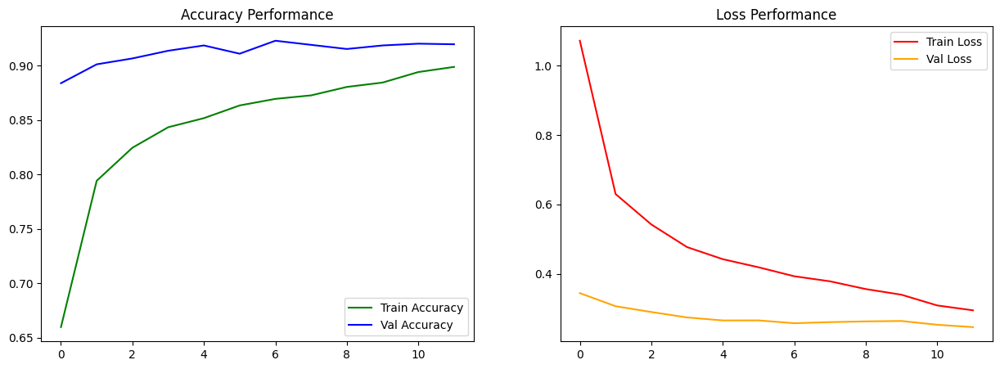

Final Model Saved as bilahbeu_model_final.h5

--- Evaluasi Akhir pada Data Test ---
30/30 ━━━━━━━━━━━━━━━━━━━━ 19s 631ms/step - accuracy: 0.9528 - loss: 0.1470
Test Accuracy: 95.28%


In [31]:
#--------13.proses training-------#

import matplotlib.pyplot as plt
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense

# 1. Pastikan jumlah output model sesuai dengan data (10 kelas)
num_classes = train_generator.num_classes
if model.layers[-1].units != num_classes:
    print(f"Menyesuaikan output model: {model.layers[-1].units} -> {num_classes}")
    # Ambil output dari lapisan sebelum Dense terakhir
    new_output = Dense(num_classes, activation='softmax', name='final_output')(model.layers[-2].output)
    model = Model(inputs=model.input, outputs=new_output)

# 2. Compiling the Model
model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# 3. Training the Model
history = model.fit(
    train_generator,
    epochs=50,
    validation_data=validation_generator,
    callbacks=callback_list
)

# 4. Plotting Performance
plt.figure(figsize=(15, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy', color='green')
plt.plot(history.history['val_accuracy'], label='Val Accuracy', color='blue')
plt.title('Accuracy Performance')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss', color='red')
plt.plot(history.history['val_loss'], label='Val Loss', color='orange')
plt.title('Loss Performance')
plt.legend()
plt.show()

# 5. Saving the Final Model
model.save("bilahbeu_model_final.h5")
print("Final Model Saved as bilahbeu_model_final.h5")

# 6. Evaluating the Model
print("\n--- Evaluasi Akhir pada Data Test ---")
test_loss, test_accuracy = model.evaluate(test_generator)
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

In [32]:
#--------14.lihat hasil-------#

from sklearn.metrics import classification_report
import numpy as np

test_generator.reset()
y_pred = model.predict(test_generator)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true = test_generator.classes
class_labels = list(test_generator.class_indices.keys())

print("\nClassification Report:\n", classification_report(y_true, y_pred_classes, target_names=class_labels))

30/30 ━━━━━━━━━━━━━━━━━━━━ 14s 305ms/step

Classification Report:
                      precision    recall  f1-score   support

      Botol Plastik       0.94      0.93      0.94       106
               Kaca       0.88      0.94      0.91       103
  Kardus dan Kertas       0.97      0.95      0.96       100
       Makanan Sisa       0.99      0.88      0.93       107
              Metal       0.94      0.97      0.96        88
            Pakaian       0.98      1.00      0.99        91
            Plastik       1.00      0.95      0.97        76
Sisa Buah dan Sayur       0.90      0.95      0.93        87
           Tumbuhan       0.95      1.00      0.97        71
            battery       0.99      0.98      0.99       104

           accuracy                           0.95       933
          macro avg       0.95      0.96      0.95       933
       weighted avg       0.95      0.95      0.95       933



30/30 ━━━━━━━━━━━━━━━━━━━━ 3s 113ms/step


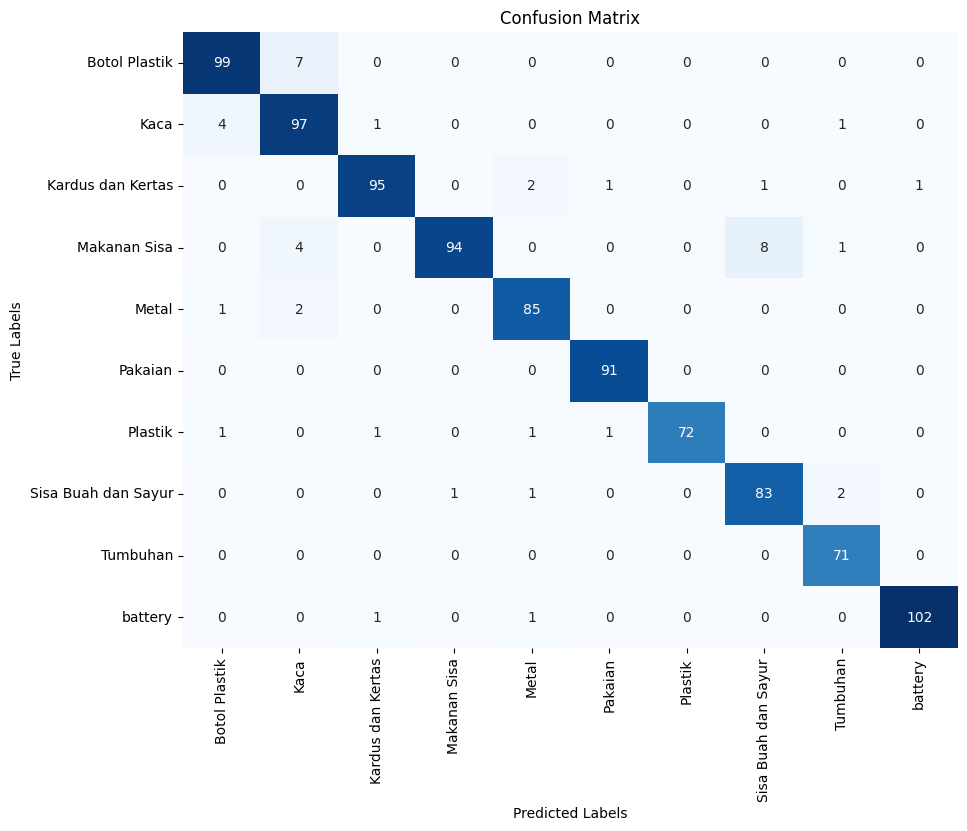

In [33]:
# Import additional necessary libraries
import numpy as np
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Make predictions on the test data
test_predictions = model.predict(test_generator, verbose=1)

# Convert predictions to label indices
predicted_labels = np.argmax(test_predictions, axis=1)

# Get the true labels from the test_generator
true_labels = test_generator.classes

# Generate the confusion matrix
cm = confusion_matrix(true_labels, predicted_labels)

# Plot confusion matrix using seaborn heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=test_generator.class_indices.keys(),
            yticklabels=test_generator.class_indices.keys(), cbar=False)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()



# Model prediction

In [ ]:
#download model .h5 di dalam drive tersebut
# https://drive.google.com/file/d/1uBkwwF90_tKtQyk4d-qLGtT4CJzHuF9A/view

Menggunakan gambar: Battery_919.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
Predicted class: battery
Confidence score: 99.98%


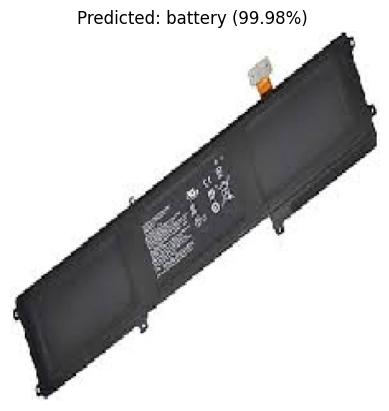

In [37]:
#--------15.tes model-------#
import os
import random

# Load the trained model
model = load_model('bilahbeu_model_final.h5')

# Set image size and folder path
IMG_SIZE = (224, 224)
test_battery_dir = "/content/dataset_model/test/battery"

# Ambil gambar random dari folder battery
random_file = random.choice(os.listdir(test_battery_dir))
img_path = os.path.join(test_battery_dir, random_file)
print(f"Menggunakan gambar: {random_file}")

# Preprocess the image
img = image.load_img(img_path, target_size=IMG_SIZE)
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)
img_array = img_array / 255.0

# Make a prediction
predictions = model.predict(img_array)
predicted_class_index = np.argmax(predictions, axis=1)[0]
predicted_class = reversed_labels[predicted_class_index]
confidence_score = predictions[0][predicted_class_index] * 100

# Output results
print(f"Predicted class: {predicted_class}")
print(f"Confidence score: {confidence_score:.2f}%")

# Display the image
plt.imshow(img)
plt.title(f"Predicted: {predicted_class} ({confidence_score:.2f}%) ")
plt.axis('off')
plt.show()

Menggunakan gambar: Sisa_Buah_dan_Sayur_108.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
Predicted class: Sisa Buah dan Sayur
Confidence score: 93.52%


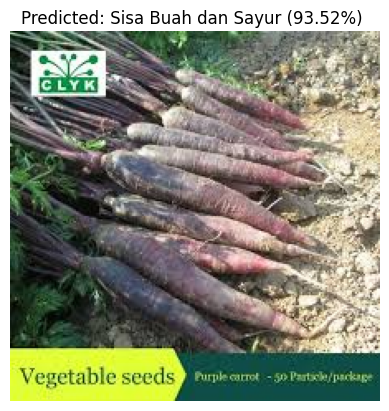

In [44]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image
from tensorflow.keras.models import load_model

# Load the trained model
model = load_model('bilahbeu_model_final.h5')

# Set image size and folder path
IMG_SIZE = (224, 224)
test_folder = "/content/dataset_model/test/Sisa Buah dan Sayur"

# Ambil gambar random dari folder Sisa Buah dan Sayur
random_file = random.choice(os.listdir(test_folder))
img_path = os.path.join(test_folder, random_file)
print(f"Menggunakan gambar: {random_file}")

# Preprocess the image
img = image.load_img(img_path, target_size=IMG_SIZE)
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)
img_array = img_array / 255.0

# Make a prediction
predictions = model.predict(img_array)
predicted_class_index = np.argmax(predictions, axis=1)[0]
confidence_score = predictions[0][predicted_class_index] * 100

# Get class labels from training directory structure
train_dir = "/content/dataset_model/train"
class_labels = sorted(os.listdir(train_dir))
predicted_class = class_labels[predicted_class_index]

# Output results
print(f"Predicted class: {predicted_class}")
print(f"Confidence score: {confidence_score:.2f}%")

# Display the image
plt.imshow(img)
plt.title(f"Predicted: {predicted_class} ({confidence_score:.2f}%) ")
plt.axis('off')
plt.show()

Menggunakan gambar: Pakaian_950.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
Predicted class: Pakaian
Confidence score: 100.00%


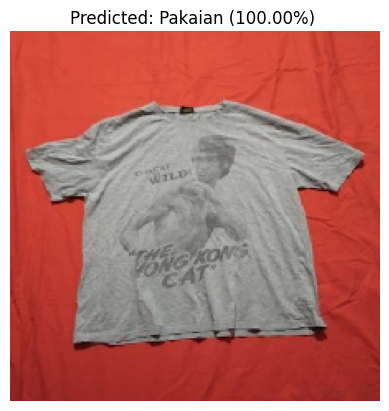

In [45]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image
from tensorflow.keras.models import load_model

# Load the trained model
model = load_model('final_model_weights.keras')

# Set image size and folder path
IMG_SIZE = (224, 224)
test_folder = "/content/dataset_model/test/Pakaian"

# Ambil gambar random dari folder Pakaian
random_file = random.choice(os.listdir(test_folder))
img_path = os.path.join(test_folder, random_file)
print(f"Menggunakan gambar: {random_file}")

# Preprocess the image
img = image.load_img(img_path, target_size=IMG_SIZE)
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)
img_array = img_array / 255.0

# Make a prediction
predictions = model.predict(img_array)
predicted_class_index = np.argmax(predictions, axis=1)[0]
# Menggunakan confidence_score dari hasil prediksi saat ini
confidence_score = predictions[0][predicted_class_index] * 100

# Get class labels from training directory structure
train_dir = "/content/dataset_model/train"
class_labels = sorted(os.listdir(train_dir))
predicted_class = class_labels[predicted_class_index]

# Output results
print(f"Predicted class: {predicted_class}")
print(f"Confidence score: {confidence_score:.2f}%")

# Display the image
plt.imshow(img)
plt.title(f"Predicted: {predicted_class} ({confidence_score:.2f}%) ")
plt.axis('off')
plt.show()

In [47]:
import shutil
import os

# Define source and destination paths
source_path = '/content/bilahbeu_model_final.h5'
destination_dir = '/content/drive/MyDrive/dataset'
destination_path = os.path.join(destination_dir, os.path.basename(source_path))

# Check if source exists and copy
if os.path.exists(source_path):
    shutil.copy(source_path, destination_path)
    print(f"Model successfully copied to: {destination_path}")
else:
    print(f"Error: {source_path} not found in the current directory.")

Model successfully copied to: /content/drive/MyDrive/dataset/bilahbeu_model_final.h5


In [48]:
#--------17. konversi .keras ke tfjs graphmodel-------#

import tensorflow as tf
import os

# Load the trained model from Drive
model_path = '/content/drive/MyDrive/dataset/final_model_weights.keras'
model = tf.keras.models.load_model(model_path)
model.summary()

# Export to SavedModel format as an intermediate step
export_path = '/content/saved_model_bilahbeu'
model.export(export_path)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 7, 7, 1280)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 62720)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 62720)          │       250,880 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │    32,113,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 99,601,888 (379.95 MB)

 Trainable params: 32,405,642 (123.62 MB)

 Non-trainable params: 2,384,960 (9.10 MB)

 Optimizer params: 64,811,286 (247.24 MB)

Saved artifact at '/content/saved_model_bilahbeu'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_layer_2')
Output Type:
  TensorSpec(shape=(None, 10), dtype=tf.float32, name=None)
Captures:
  133526707691856: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133526707690128: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133526707690320: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133526707690704: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133526707689744: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133526707690896: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133526707689936: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133526707689552: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133526707692048: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133526707683984: TensorSpec(shape=(), dtype=tf.resource, name=None)
 

In [49]:
import sys

# Convert SavedModel to tfjs GRAPH model format
# Menggunakan python -m tensorflowjs.converters.converter untuk memastikan command ditemukan
!{sys.executable} -m tensorflowjs.converters.converter \
  --input_format=tf_saved_model \
  --output_format=tfjs_graph_model \
  --signature_name=serving_default \
  /content/saved_model_bilahbeu \
  /content/web_model_graph

2026-05-17 08:46:02.115989: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1779007562.349281   49260 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1779007562.402428   49260 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1779007562.655607   49260 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1779007562.655658   49260 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1779007562.655666   49260 computation_placer.cc:177] computation placer alr

In [50]:
import json
# Verify the output format
with open('/content/web_model_graph/model.json') as f:
    meta = json.load(f)
print('Format:', meta.get('format'))
# Should print: Format: graph-model

Format: graph-model


In [51]:
import shutil

# Save directly to Google Drive instead of browser download
drive_zip_path = '/content/drive/MyDrive/dataset/web_model_graph'
shutil.make_archive(drive_zip_path, 'zip', '/content/web_model_graph')

print(f"Success! Graph model ZIP saved to: {drive_zip_path}.zip")

Success! Graph model ZIP saved to: /content/drive/MyDrive/dataset/web_model_graph.zip


# Implementasi Custom Training Loop

In [52]:
import tensorflow as tf
import time
from tqdm import tqdm # Tambahkan ini untuk progress bar

# 1. Definisi Loss dan Optimizer
loss_object = tf.keras.losses.CategoricalCrossentropy(from_logits=False)
optimizer = tf.keras.optimizers.Adam(learning_rate=0.0001)

# 2. Definisi Metrik
train_loss = tf.keras.metrics.Mean(name='train_loss')
train_accuracy = tf.keras.metrics.CategoricalAccuracy(name='train_accuracy')
val_loss = tf.keras.metrics.Mean(name='val_loss')
val_accuracy = tf.keras.metrics.CategoricalAccuracy(name='val_accuracy')

# 3. Fungsi Train Step (Dioptimalkan)
@tf.function
def train_step(images, labels):
    with tf.GradientTape() as tape:
        predictions = model(images, training=True)
        # Hitung base loss
        base_loss = loss_object(labels, predictions)
        # Tambahkan regularization loss (jika ada di layer model)
        total_loss = base_loss + tf.add_n(model.losses) if model.losses else base_loss

    gradients = tape.gradient(total_loss, model.trainable_variables)
    optimizer.apply_gradients(zip(gradients, model.trainable_variables))

    train_loss(total_loss)
    train_accuracy(labels, predictions)

# 4. Fungsi Validation Step
@tf.function
def val_step(images, labels):
    predictions = model(images, training=False)
    v_loss = loss_object(labels, predictions)
    # Untuk validasi, kita juga tambahkan reg_loss agar apple-to-apple dengan train_loss
    total_v_loss = v_loss + tf.add_n(model.losses) if model.losses else v_loss

    val_loss(total_v_loss)
    val_accuracy(labels, predictions)

# 5. Training Loop Utama
EPOCHS = 15
print(f"Memulai Custom Training Loop untuk {EPOCHS} Epoch...\n")

for epoch in range(EPOCHS):
    start_time = time.time()

    # Reset metrik
    train_loss.reset_state()
    train_accuracy.reset_state()
    val_loss.reset_state()
    val_accuracy.reset_state()

    # Iterasi Training dengan Progress Bar
    print(f"Epoch {epoch + 1}/{EPOCHS}")
    pb_train = tqdm(range(len(train_generator)), desc="Training")
    for step in pb_train:
        images, labels = next(train_generator)
        train_step(images, labels)
        # Update info di progress bar
        pb_train.set_postfix({"loss": f"{train_loss.result():.4f}", "acc": f"{train_accuracy.result():.4f}"})

    # Iterasi Validation
    pb_val = tqdm(range(len(validation_generator)), desc="Validation")
    for step in pb_val:
        images, labels = next(validation_generator)
        val_step(images, labels)

    template = 'Epoch {:d}: Loss: {:.4f}, Acc: {:.4f}, Val Loss: {:.4f}, Val Acc: {:.4f}, Waktu: {:.2f}s\n'
    print(template.format(epoch + 1,
                         train_loss.result(),
                         train_accuracy.result(),
                         val_loss.result(),
                         val_accuracy.result(),
                         time.time() - start_time))

# Simpan model secara manual setelah loop selesai
model.save("custom_train_model.h5")

Memulai Custom Training Loop untuk 15 Epoch...

Epoch 1/15


Training:  26%|██▌       | 80/311 [00:58<02:00,  1.92it/s, loss=0.3618, acc=0.8797]/usr/local/lib/python3.12/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
Validation: 100%|██████████| 58/58 [00:12<00:00,  4.53it/s]


Epoch 1: Loss: 0.3849, Acc: 0.8708, Val Loss: 0.2739, Val Acc: 0.9214, Waktu: 212.98s

Epoch 2/15


Validation: 100%|██████████| 58/58 [00:10<00:00,  5.70it/s]


Epoch 2: Loss: 0.3823, Acc: 0.8711, Val Loss: 0.2428, Val Acc: 0.9192, Waktu: 195.31s

Epoch 3/15


Validation: 100%|██████████| 58/58 [00:09<00:00,  5.85it/s]


... (21 outputs left out)

Validation: 100%|██████████| 58/58 [00:09<00:00,  6.35it/s]


Epoch 14: Loss: 0.2320, Acc: 0.9229, Val Loss: 0.2465, Val Acc: 0.9284, Waktu: 195.90s

Epoch 15/15


Validation: 100%|██████████| 58/58 [00:10<00:00,  5.69it/s]


Epoch 15: Loss: 0.2475, Acc: 0.9142, Val Loss: 0.2477, Val Acc: 0.9279, Waktu: 195.11s



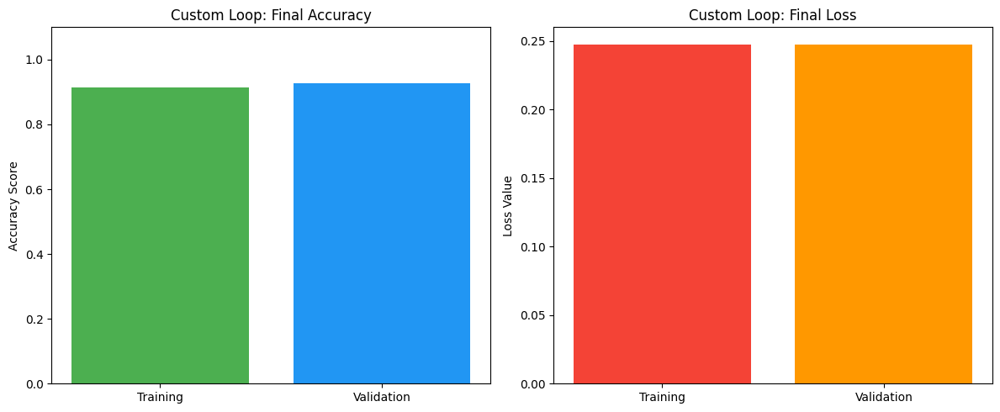

In [53]:
import matplotlib.pyplot as plt
import numpy as np

# Mengambil hasil akhir dari objek metrik custom training loop
# Karena custom loop Anda tidak menghasilkan objek 'history', kita ambil hasil result() nya
train_acc_final = train_accuracy.result().numpy()
val_acc_final = val_accuracy.result().numpy()
train_loss_final = train_loss.result().numpy()
val_loss_final = val_loss.result().numpy()

# Setup Visualisasi Line Chart
# Catatan: Untuk grafik garis progres per epoch, idealnya data disimpan dalam list di dalam loop.
# Jika Anda ingin melihat progres per epoch, Anda perlu menjalankan ulang loop dengan menyimpan hasil ke list.
# Kode di bawah ini menampilkan perbandingan Training vs Validation saat ini.

labels = ['Training', 'Validation']
acc_scores = [train_acc_final, val_acc_final]
loss_scores = [train_loss_final, val_loss_final]

plt.figure(figsize=(12, 5))

# Plot Akurasi
plt.subplot(1, 2, 1)
plt.bar(labels, acc_scores, color=['#4CAF50', '#2196F3'])
plt.title('Custom Loop: Final Accuracy')
plt.ylabel('Accuracy Score')
plt.ylim(0, 1.1)

# Plot Loss
plt.subplot(1, 2, 2)
plt.bar(labels, loss_scores, color=['#F44336', '#FF9800'])
plt.title('Custom Loop: Final Loss')
plt.ylabel('Loss Value')

plt.tight_layout()
plt.show()

In [54]:
import shutil
import os

# Tentukan path asal dan tujuan
source_path = 'custom_train_model.h5'
destination_dir = '/content/drive/MyDrive/dataset'
destination_path = os.path.join(destination_dir, source_path)

# Pastikan folder tujuan ada
os.makedirs(destination_dir, exist_ok=True)

# Salin file
if os.path.exists(source_path):
    shutil.copy(source_path, destination_path)
    print(f"Berhasil menyalin model ke: {destination_path}")
else:
    print(f"Error: File {source_path} tidak ditemukan di direktori saat ini.")

Berhasil menyalin model ke: /content/drive/MyDrive/dataset/custom_train_model.h5


Menggunakan gambar random: /content/dataset_model/test/Pakaian/Pakaian_018.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 7s 7s/step
Predicted class: Pakaian
Confidence score: 100.00%


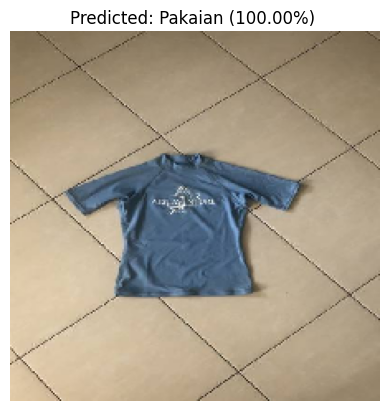

In [58]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image
from tensorflow.keras.models import load_model

# Load the trained model
model = load_model('custom_train_model.h5')

# Set image size and test folder path
IMG_SIZE = (224, 224)
test_root = "/content/dataset_model/test"

# Fungsi untuk mengambil gambar random dari subfolder mana saja di dalam folder test
all_test_images = []
for root, dirs, files in os.walk(test_root):
    for file in files:
        if file.lower().endswith(('.png', '.jpg', '.jpeg')):
            all_test_images.append(os.path.join(root, file))

img_path = random.choice(all_test_images)
print(f"Menggunakan gambar random: {img_path}")

# Preprocess the image
img = image.load_img(img_path, target_size=IMG_SIZE)
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)
img_array = img_array / 255.0

# Make a prediction
predictions = model.predict(img_array)
predicted_class_index = np.argmax(predictions, axis=1)[0]
confidence_score = predictions[0][predicted_class_index] * 100

# Get class labels from training directory
train_dir = "/content/dataset_model/train"
class_labels = sorted(os.listdir(train_dir))
predicted_class = class_labels[predicted_class_index]

# Output results
print(f"Predicted class: {predicted_class}")
print(f"Confidence score: {confidence_score:.2f}%")

# Display the image
plt.imshow(img)
plt.title(f"Predicted: {predicted_class} ({confidence_score:.2f}%) ")
plt.axis('off')
plt.show()

In [61]:
import shutil
import os

# Tentukan path asal dan tujuan
log_source = '/content/logs'
log_destination = '/content/drive/MyDrive/dataset/logs_backup'

# Periksa apakah folder log ada
if os.path.exists(log_source):
    # Hapus folder tujuan jika sudah ada agar tidak error saat menyalin
    if os.path.exists(log_destination):
        shutil.rmtree(log_destination)

    # Salin seluruh folder log
    shutil.copytree(log_source, log_destination)
    print(f"Berhasil menyalin log ke: {log_destination}")
else:
    print(f"Error: Folder log di {log_source} tidak ditemukan.")

Berhasil menyalin log ke: /content/drive/MyDrive/dataset/logs_backup


In [59]:
%load_ext tensorboard
import tensorflow as tf

# Menampilkan log dari direktori spesifik yang Anda minta
%tensorboard --logdir /content/logs/fit/20260517-073705

Output hidden; open in https://colab.research.google.com to view.